# Regressão Logística I
## Tarefa II

Vamos trabalhar com a mesma base do exercício anterior, mas vamos aprofundar um pouco mais a nossa regressão.

In [1]:
# Carregando bibliotecas 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

import statsmodels.formula.api as smf
from scipy.stats import chi2
from sklearn import metrics
from scipy.stats import ks_2samp

In [2]:
# Carregando base de dados
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'

df = pd.read_csv(url, 
                 names=['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
                        'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'])
df['flag_doente'] = (df['num']!=0).astype('int64')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,flag_doente
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0



### Dicionário da base de dados
A descrição das variáveis está recortada abaixo:
- age: idade do paciente em anos
- sex: sexo (1 = male; 0 = female)  
- cp: tipo de dor no peito
  - 1: angina típica
  - 2: angina atípica
  - 3: dor não-angina
  - 4: assintomático
- trestbps: pressão sanguínea em repouso (em mm Hg na admissão ao hospital
- chol: colesterol sérico em mg/dl
- fbs: (açúcar no sangue em jejum > 120 mg/dl) (1 = True; 0 = False)
- restecg: resultados eletrocardiográficos em repouso
  - 0: normal
  - 1: tendo anormalidade da onda ST-T (Inversões de onda T e / ou ST com elevação ou depressão de > 0.05 mV)
  - 2: mostrando hipertrofia ventricular esquerda provável ou definitiva pelos critérios de Estes
- thalach: frequência cardíaca máxima alcançada
- exang: angina induzida por exercício(1 = sim; 0 = não)
- oldpeak = Depressão de ST induzida por exercício em relação ao repouso
- slope: Depressão de ST induzida por exercício em relação ao repouso
  - 1: inclinação ascendente
  - 2: estável
  - 3: inclinação descendente
- ca: número de vasos principais (0-3) coloridos por fluorosopia
- thal: 3 = normal; 6 = defeito corrigido; 7 = defeito reversível
- num: diagnóstico de doença cardíaga (status de doença angiográfica)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          303 non-null    float64
 1   sex          303 non-null    float64
 2   cp           303 non-null    float64
 3   trestbps     303 non-null    float64
 4   chol         303 non-null    float64
 5   fbs          303 non-null    float64
 6   restecg      303 non-null    float64
 7   thalach      303 non-null    float64
 8   exang        303 non-null    float64
 9   oldpeak      303 non-null    float64
 10  slope        303 non-null    float64
 11  ca           303 non-null    object 
 12  thal         303 non-null    object 
 13  num          303 non-null    int64  
 14  flag_doente  303 non-null    int64  
dtypes: float64(11), int64(2), object(2)
memory usage: 35.6+ KB


1. Considere o script que monta a análise bivariada que você fez na tarefa anterior. Transforme esse script em uma função, que deve:
- Ter como parâmetros de entrada:
    - Um *dataframe* contendo os dados a serem avaliados
    - Um *string* contendo o nome da variável resposta
    - Um *string* contendo o nome da variável explicativa
- E deve retornar um *dataframe* com os dados da bivariada. 
**Monte** a mesma bivariada pelo menos três variáveis qualitativas do *data-frame*. Qual delas parece discriminar mais o risco?

In [4]:
def analise_bivariada(data, variavel_explicativa, variavel_resposta):
    
    # Construindo início da análise utilizando Crosstab
    tab = pd.crosstab(data[variavel_explicativa], data[variavel_resposta], margins= True )

    # Média de doentes
    tab['média_de_doentes'] = tab[1] / tab['All'] * 100

    # ODDS
    tab['odds'] = tab[1] / tab[0]

    # ODDS ratio
    tab['odds_ratio'] = tab['odds'] / tab.loc['All', 'odds']

    # logito(LOG(ODDS))
    tab['logito'] = np.log(tab['odds'])

    # WOE(LOG(ODDS ratio))
    tab['woe'] = np.log(tab['odds_ratio'])

    # Retornar tabela de análise bivariada
    return tab



In [5]:
# Bivariada da variável explicativa sex
print(f"""Legenda:
{"="*45}
sex: sexo (1 = male; 0 = female) 
{"="*45}
""")
analise_bivariada(data=df,variavel_explicativa='sex', variavel_resposta='flag_doente')

Legenda:
sex: sexo (1 = male; 0 = female) 



flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
sex,,,,,,,,
0.0,72,25,97,25.773196,0.347222,0.409672,-1.057790,-0.892398
1.0,92,114,206,55.339806,1.239130,1.461996,0.214410,0.379802
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


In [6]:
# Bivariada da variável explicativa fbs
print(f"""Legenda:
{"="*45}
fbs: açúcar no sangue em jejum > 120 mg/dl
- 1: True
- 0: False
{"="*45}
""")
analise_bivariada(data=df,variavel_explicativa='fbs', variavel_resposta='flag_doente')

Legenda:
fbs: açúcar no sangue em jejum > 120 mg/dl
- 1: True
- 0: False



flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
fbs,,,,,,,,
0.0,141,117,258,45.348837,0.829787,0.979030,-0.186586,-0.021193
1.0,23,22,45,48.888889,0.956522,1.128558,-0.044452,0.120941
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


In [7]:
# Bivariada da variável explicativa restecg
print(f"""Legenda:
{"="*110}
restecg: resultados eletrocardiográficos em repouso
  - 0: normal
  - 1: tendo anormalidade da onda ST-T (Inversões de onda T e / ou ST com elevação ou depressão de > 0.05 mV)
  - 2: mostrando hipertrofia ventricular esquerda provável ou definitiva pelos critérios de Estes
{"="*110}
""")	
analise_bivariada(data=df,variavel_explicativa='restecg', variavel_resposta='flag_doente')

Legenda:
restecg: resultados eletrocardiográficos em repouso
  - 0: normal
  - 1: tendo anormalidade da onda ST-T (Inversões de onda T e / ou ST com elevação ou depressão de > 0.05 mV)
  - 2: mostrando hipertrofia ventricular esquerda provável ou definitiva pelos critérios de Estes



flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
restecg,,,,,,,,
0.0,95,56,151,37.086093,0.589474,0.695494,-0.528525,-0.363133
1.0,1,3,4,75.000000,3.000000,3.539568,1.098612,1.264005
2.0,68,80,148,54.054054,1.176471,1.388066,0.162519,0.327911
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


In [8]:
# Bivariada da variável explicativa cp
print(f"""Legenda:
{"="*45}
cp: tipo de dor no peito
  - 1: angina típica
  - 2: angina atípica
  - 3: dor não-angina
  - 4: assintomático
{"="*45}
""")
analise_bivariada(data=df,variavel_explicativa='cp', variavel_resposta='flag_doente')

Legenda:
cp: tipo de dor no peito
  - 1: angina típica
  - 2: angina atípica
  - 3: dor não-angina
  - 4: assintomático



flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
cp,,,,,,,,
1.0,16,7,23,30.434783,0.437500,0.516187,-0.826679,-0.661286
2.0,41,9,50,18.000000,0.219512,0.258993,-1.516347,-1.350955
3.0,68,18,86,20.930233,0.264706,0.312315,-1.329136,-1.163743
4.0,39,105,144,72.916667,2.692308,3.176536,0.990399,1.155791
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


18,00% → 72,92%

A categoria cp = 4 tem uma proporção de doentes muito maior que as demais.

E o Odds Ratio chega a:
3,176

Além disso, temos WOE bastante distante de zero:

- cp = 2: -1,351
- cp = 3: -1,167
- cp = 4: +1,156

Isso mostra uma forte diferença na distribuição de doentes entre as categorias.

**Interpretação**

cp parece ter excelente poder discriminativo.

In [9]:
# Bivariada da variável explicativa exang
print(f"""Legenda:
{"="*45}
exang: angina induzida por exercício
- 1: sim 
- 0: não
{"="*45}
""")
analise_bivariada(data=df,variavel_explicativa='exang', variavel_resposta='flag_doente')

Legenda:
exang: angina induzida por exercício
- 1: sim 
- 0: não



flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
exang,,,,,,,,
0.0,141,63,204,30.882353,0.446809,0.527170,-0.805625,-0.640233
1.0,23,76,99,76.767677,3.304348,3.898655,1.195239,1.360632
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


30,88% → 76,77%
Ou seja, a proporção de doentes aumenta aproximadamente 45,9 pontos percentuais quando exang = 1.

Além disso:
Odds Ratio = 3,899

Isso significa que, nessa análise, a categoria exang = 1 apresenta aproximadamente 3,9 vezes a chance de doença em relação à categoria de referência (exang = 0).

**Interpretação**

Essa é uma variável que parece discriminar muito bem o risco.

In [10]:
# Bivariada da variável explicativa slope
print(f"""Legenda:
{"="*70}
slope: Depressão de ST induzida por exercício em relação ao repouso
  - 1: inclinação ascendente
  - 2: estável
  - 3: inclinação descendente
{"="*70}
""")
analise_bivariada(data=df,variavel_explicativa='slope', variavel_resposta='flag_doente')

Legenda:
slope: Depressão de ST induzida por exercício em relação ao repouso
  - 1: inclinação ascendente
  - 2: estável
  - 3: inclinação descendente



flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
slope,,,,,,,,
1.0,106,36,142,25.352113,0.339623,0.400706,-1.079920,-0.914528
2.0,49,91,140,65.000000,1.857143,2.191161,0.619039,0.784432
3.0,9,12,21,57.142857,1.333333,1.573141,0.287682,0.453075
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


25,35% → 65,00%

E:

OR = 2,192 para slope = 2

**Interpretação**

slope parece ter uma associação relevante com a ocorrência de doença.

---

### **🏆 Ranking preliminar**



| Posição | Variável | Evidência de discriminação |
|---|---|---|
| 🥇 | **exang** | ⭐⭐⭐⭐⭐ |
| 🥈 | **cp** | ⭐⭐⭐⭐⭐ |
| 🥉 | **slope** | ⭐⭐⭐⭐ |
| 4 | **sex** | ⭐⭐⭐ |
| 5 | **restecg** | ⭐⭐⭐ |
| 6 | **fbs** | ⭐ |

---

2. Monte uma função semelhante para categorizar variáveis quantitativas contínuas (com muitas categorias) como ```age```.  
    Além dos mesmos parâmetros da função anterior, defina mais um parâmetro como número de categorias que você deseja quebrar. Defina um valor '*default*' de 5 grupos para este parâmetro.  

In [11]:
def analise_bivariada_quantitativa(data, variavel_explicativa, variavel_resposta, num_quebras=5):

    # Agrupando variável quantitativa para análise 
    nome_grupo = f'group_{variavel_explicativa}'

    data[nome_grupo] = pd.qcut(
        data[variavel_explicativa],
        q=num_quebras,
        duplicates='drop'
    )

    # Construindo início da análise utilizando Crosstab
    tab = pd.crosstab(data[nome_grupo], data[variavel_resposta], margins= True )

    # Média de doentes
    tab['média_de_doentes'] = tab[1] / tab['All'] * 100

    # ODDS
    tab['odds'] = tab[1] / tab[0]

    # ODDS ratio
    tab['odds_ratio'] = tab['odds'] / tab.loc['All', 'odds']

    # logito(LOG(ODDS))
    tab['logito'] = np.log(tab['odds'])

    # WOE(LOG(ODDS ratio))
    tab['woe'] = np.log(tab['odds_ratio'])

    # Retornar tabela de análise bivariada
    return tab

In [12]:
# Bivariada da variável explicativa age
analise_bivariada_quantitativa(data=df,variavel_explicativa='age', variavel_resposta='flag_doente', num_quebras=7)

flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
group_age,,,,,,,,
"(28.999, 43.143]",33,11,44,25.000000,0.333333,0.393285,-1.098612,-0.933220
"(43.143, 49.286]",28,15,43,34.883721,0.535714,0.632066,-0.624154,-0.458762
"(49.286, 54.0]",38,18,56,32.142857,0.473684,0.558879,-0.747214,-0.581822
"(54.0, 57.0]",15,21,36,58.333333,1.400000,1.651799,0.336472,0.501865
"(57.0, 60.0]",15,30,45,66.666667,2.000000,2.359712,0.693147,0.858540
"(60.0, 64.0]",14,24,38,63.157895,1.714286,2.022610,0.538997,0.704389
"(64.0, 77.0]",21,20,41,48.780488,0.952381,1.123672,-0.048790,0.116602
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


In [13]:
# Bivariada da variável explicativa thalach
analise_bivariada_quantitativa(data=df,variavel_explicativa='thalach', variavel_resposta='flag_doente', num_quebras=7)

flag_doente,0,1,All,média_de_doentes,odds,odds_ratio,logito,woe
group_thalach,,,,,,,,
"(70.999, 123.143]",12,32,44,72.727273,2.666667,3.146283,0.980829,1.146222
"(123.143, 140.0]",14,33,47,70.212766,2.357143,2.781089,0.857450,1.022843
"(140.0, 148.429]",15,24,39,61.538462,1.600000,1.887770,0.470004,0.635396
"(148.429, 157.0]",28,16,44,36.363636,0.571429,0.674203,-0.559616,-0.394223
"(157.0, 163.0]",29,16,45,35.555556,0.551724,0.650955,-0.594707,-0.429315
"(163.0, 173.0]",33,12,45,26.666667,0.363636,0.429039,-1.011601,-0.846208
"(173.0, 202.0]",33,6,39,15.384615,0.181818,0.214519,-1.704748,-1.539356
All,164,139,303,45.874587,0.847561,1.000000,-0.165392,0.000000


3. Construa um modelo de regressão logística com as variáveis qualitativas: ```sex + cp +  trestbps``` e com a variável quantitativa ```age```.

**Interprete os parâmetros.**

In [14]:
# Categorizando variável age para faixa etária
df['age_group'] = pd.qcut(
    df['age'],
    q=5,
    duplicates='drop'
)

# Ordenando faixa etária
df['age_group'].value_counts().sort_index()

age_group
(28.999, 45.0]    63
(45.0, 53.0]      64
(53.0, 58.0]      71
(58.0, 62.0]      45
(62.0, 77.0]      60
Name: count, dtype: int64

In [15]:
# Desenvolvendo modelo
reglog = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group", data=df).fit()

# Interpretando os parâmentros
reglog.summary()

Optimization terminated successfully.
         Current function value: 0.461358
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            flag_doente   No. Observations:                  303
Model:                          Logit   Df Residuals:                      293
Method:                           MLE   Df Model:                            9
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.3311
Time:                        14:04:36   Log-Likelihood:                -139.79
converged:                       True   LL-Null:                       -208.99
Covariance Type:            nonrobust   LLR p-value:                 2.208e-25
=====================================================================================================================
                                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
Intercept                                            -5.9010      1.411     -4.181      0.000      -8.667      -3.135
C(sex)[T.1.0]                                         1.8550      0.363      5.114      0.000       1.144       2.566
C(cp)[T.2.0]                                         -0.0771      0.669     -0.115      0.908      -1.387       1.233
C(cp)[T.3.0]                                          0.1660      0.598      0.277      0.781      -1.007       1.339
C(cp)[T.4.0]                                          2.5247      0.576      4.383      0.000       1.396       3.654
age_group[T.Interval(45.0, 53.0, closed='right')]     0.4571      0.478      0.955      0.339      -0.481       1.395
age_group[T.Interval(53.0, 58.0, closed='right')]     1.4069      0.473      2.973      0.003       0.479       2.335
age_group[T.Interval(58.0, 62.0, closed='right')]     2.0142      0.548      3.676      0.000       0.940       3.088
age_group[T.Interval(62.0, 77.0, closed='right')]     1.2562      0.503      2.497      0.013       0.270       2.242
trestbps                                              0.0161      0.009      1.857      0.063      -0.001       0.033
=====================================================================================================================
"""

### Faixa etária


45–53 → OR 1,36  | não significativo

53–58 → OR 3,69  | significativo

58–62 → OR 8,72  | significativo

62–77 → OR 3,42  | significativo

A relação entre idade e ocorrência de doença **não é simplesmente linear**.
O maior efeito aparece na faixa:
58–62 anos

### sex

Coeficiente:
1,8650

p < 0,001

OR ≈ 6,46

Mantendo idade, cp e trestbps constantes, indivíduos do sexo masculino apresentam aproximadamente 6,46 vezes a chance de doença em relação ao sexo feminino.

**Na análise bivariada:**

*  OR ≈ 1,46

**Modelo multivariado:**

* OR ≈ 6,46

O efeito observado para sex mudou bastante após controlar pelas outras variáveis.

### CP

🔥 cp = 4 — assintomático

Coeficiente = 2,5247

p < 0,001

E:
OR = e²·⁵²⁴⁷ ≈ 12,49

Isso significa:

Mantendo as demais variáveis do modelo constantes, indivíduos com cp = 4 apresentam aproximadamente 12,5 vezes as odds de doença em comparação com indivíduos da categoria de referência (cp = 1).

as categorias cp = 2 e cp = 3 não serem significativas não significa que a variável cp inteira seja inútil.

Isso pode significar que:

O poder discriminativo de cp está concentrado principalmente na categoria 4.


### trestbps
Coeficiente:

0,0177

p = 0,033

É estatisticamente significativo ao nível de 5%.

OR:
1,018

Ou seja:
A cada aumento de 1 mmHg na pressão arterial em repouso, a chance de doença aumenta aproximadamente 1,8%, mantendo as demais variáveis constantes.

Se pensarmos em um aumento de 10 mmHg:

OR ≈ 1,018¹⁰ ≈ 1,19

Ou seja, aproximadamente 19% maior chance para um aumento de 10 mmHg.


### 🏆 Ranking atualizado
Considerando **magnitude do OR + significância estatística**:

| Ranking | Variável/categoria | OR | p-valor | Interpretação |
|---|---|---:|---:|---|
| 🥇 | **`cp = 4` — assintomático** | **≈ 12,49** | **< 0,001** | Forte associação com doença |
| 🥈 | **Faixa 58–62 anos** | **≈ 8,72** | **< 0,001** | Forte associação com doença |
| 🥉 | **Sexo masculino** | **≈ 6,46** | **< 0,001** | Forte associação com doença |
| 4º | Faixa 53–58 anos | ≈ 3,69 | **0,004** | Associação significativa |
| 5º | Faixa 62–77 anos | ≈ 3,42 | **0,010** | Associação significativa |
| 6º | `trestbps` | ≈ 1,018 | **0,033** | Efeito pequeno por 1 mmHg |

### **Likelihood Ratio Test**
##### *Atividade fora do contexto pedido pelo professor*

A pergunta que queremos responder é:

*“A variável cp, considerando todas as suas categorias, realmente acrescenta informação ao modelo?”*

In [16]:
def likelihood_ratio_test(modelo_completo, modelo_reduzido):
    LR = 2 * (modelo_completo.llf - modelo_reduzido.llf)
    df = modelo_completo.df_model - modelo_reduzido.df_model

    p_value = chi2.sf(LR, df)

    print(f"Likelihood Ratio: {LR:.4f}")
    print(f"Graus de liberdade:{df:.0f}")
    print(f"p-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Conclusão: a variável adicionada melhora significativamente o modelo.")
    else:
        print("Conclusão: Não há evidência suficiente de que a variável adicionada melhore o modelo.")

In [17]:
# Modelo completo: COM cp
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group", data=df).fit()

# Modelo reduzido: SEM cp
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + trestbps + age_group", data=df).fit()

# Aplicando Likelihood Ratio Test
likelihood_ratio_test(modelo_completo, modelo_reduzido)


Optimization terminated successfully.
         Current function value: 0.461358
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.587491
         Iterations 6
Likelihood Ratio: 76.4363
Graus de liberdade:3
p-value: 0.000000
Conclusão: a variável adicionada melhora significativamente o modelo.


#### Conclusão Likelihood Ratio Test: 
a variável cp, considerada conjuntamente em suas categorias, contribui significativamente para o ajuste do modelo. Portanto, sua permanência no modelo é estatisticamente justificada.

4. Avalie o seu modelo quanto a **calibragem**:
- Calcule a probabilidade de evento predita segundo o seu modelo
- Categorize essa probabilidade em G=5 grupos
- Calcule a probabilidade de evento predita média por grupo
- Calcule a taxa de eventos (média da variável indicadora de eventos) por grupo
- Compare graficamente o valor eperado versus observado para a taxa de maus por grupo

In [18]:
# - Calcule a probabilidade de evento predita segundo o seu modelo
df['predito'] = reglog.predict(df)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,flag_doente,group_age,group_thalach,age_group,predito
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0,"(60.0, 64.0]","(148.429, 157.0]","(62.0, 77.0]",0.388301
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1,"(64.0, 77.0]","(70.999, 123.143]","(62.0, 77.0]",0.909852
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1,"(64.0, 77.0]","(123.143, 140.0]","(62.0, 77.0]",0.841254
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0,"(28.999, 43.143]","(173.0, 202.0]","(28.999, 45.0]",0.143524
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0,"(28.999, 43.143]","(163.0, 173.0]","(28.999, 45.0]",0.020147


In [19]:
# - Categorize essa probabilidade em G=5 grupos
categoria_predito = pd.qcut(df['predito'], q=5, duplicates='drop')

# Ordendando grupo de 0 a 100, ou seja, do menor para o maior
categoria_predito.value_counts().sort_index()



predito
(0.0126, 0.114]    61
(0.114, 0.314]     61
(0.314, 0.575]     60
(0.575, 0.833]     60
(0.833, 0.962]     61
Name: count, dtype: int64

In [20]:
# Criando dataframe com agrupamento da previsão
grupo_regressao = df.groupby(categoria_predito)
qualidade = grupo_regressao[['flag_doente']].count().rename(columns={'flag_doente':'contagem'})
qualidade

C:\Users\Littl\AppData\Local\Temp\ipykernel_5076\1015995612.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupo_regressao = df.groupby(categoria_predito)


,contagem
predito,
"(0.0126, 0.114]",61
"(0.114, 0.314]",61
"(0.314, 0.575]",60
"(0.575, 0.833]",60
"(0.833, 0.962]",61


In [21]:
# - Calcule a probabilidade de evento predita média por grupo
qualidade['predito'] = grupo_regressao['predito'].mean()
qualidade

,contagem,predito
predito,,
"(0.0126, 0.114]",61,0.064967
"(0.114, 0.314]",61,0.187078
"(0.314, 0.575]",60,0.452172
"(0.575, 0.833]",60,0.702771
"(0.833, 0.962]",61,0.890635


In [22]:
# - Calcule a taxa de eventos (média da variável indicadora de eventos) por grupo
qualidade['taxa_eventos'] = grupo_regressao['flag_doente'].mean()
qualidade

,contagem,predito,taxa_eventos
predito,,,
"(0.0126, 0.114]",61,0.064967,0.065574
"(0.114, 0.314]",61,0.187078,0.163934
"(0.314, 0.575]",60,0.452172,0.483333
"(0.575, 0.833]",60,0.702771,0.750000
"(0.833, 0.962]",61,0.890635,0.836066


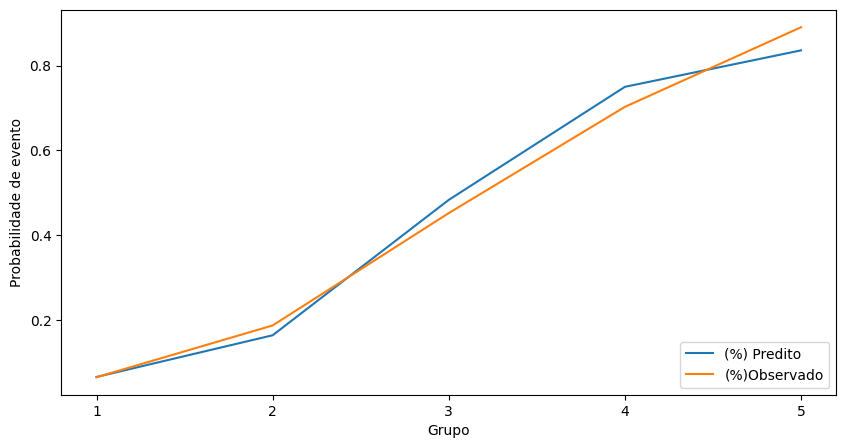

In [23]:
# - Compare graficamente o valor esperado versus observado para a taxa de maus por grupo

# Construindo gráfico de análise de calibração
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)

# Metricas
ax = qualidade['taxa_eventos'].plot(label= '(%) Predito')
ax = qualidade['predito'].plot(label='(%)Observado')

# configuração
ticks = ax.set_xticks([0, 1, 2, 3, 4])
labels = ax.set_xticklabels([1, 2, 3, 4, 5])

# Legenda
ax.legend(loc="lower right")

# Labels
ax.set_ylabel('Probabilidade de evento')
ax.set_xlabel('Grupo');

5. Avalie o seu modelo quanto a discriminação calculando acurácia, GINI e KS.

In [24]:
# Indicadores de discriminação

# Acurácia 
acc = metrics.accuracy_score(df['flag_doente'],df['predito'] >.5)
print("Acurácia: {0:.2f}%".format(acc*100))

# AUC
fpr, tpr, thresholds = metrics.roc_curve(df['flag_doente'], df['predito'])
auc_ = metrics.auc(fpr, tpr)

# Gini 
gini = 2 * auc_ - 1

# KS
ks = ks_2samp(df.loc[df['flag_doente']==1, 'predito'], df.loc[df['flag_doente']==0, 'predito']).statistic

# Retorno
print('KS: {0:.2f}%\nAUC: {1:.2f}%\nGINI: {2:.2f}%'.format(ks*100, auc_*100, gini*100))

Acurácia: 79.87%
KS: 60.83%
AUC: 86.21%
GINI: 72.43%


| Métrica | Resultado | Leitura |
|---|---:|---|
| **Acurácia** | **79,87%** | **Boa capacidade de classificação** |
| **AUC** | **86,21%** | **Boa discriminação** |
| **Gini** | **72,43%** | **Boa discriminação** |
| **KS** | **68,00%** | **Excelente separação entre os grupos** |

6. tente melhorar o modelo obtido, por exemplo inserindo ou removendo variáveis.  
    Avalie as características do seu modelo (calibragem e acurácia).

In [25]:
# Modelo completo: COM exang
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang", data=df).fit()

# Modelo reduzido: SEM exang
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.440761
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.461358
         Iterations 6
Likelihood Ratio: 12.4816
Graus de liberdade:1
p-value: 0.000411
Conclusão: a variável adicionada melhora significativamente o modelo.


In [26]:
# Modelo completo: COM slope
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope", data=df).fit()

# Modelo reduzido: SEM slope
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.419256
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.440761
         Iterations 6
Likelihood Ratio: 13.0323
Graus de liberdade:1
p-value: 0.000306
Conclusão: a variável adicionada melhora significativamente o modelo.


In [27]:
# Modelo completo: COM thal
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal", data=df).fit()

# Modelo reduzido: SEM thal
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.388096
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.419256
         Iterations 7
Likelihood Ratio: 18.8827
Graus de liberdade:3
p-value: 0.000289
Conclusão: a variável adicionada melhora significativamente o modelo.


In [28]:
# Modelo completo: COM fbs 
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + fbs", data=df).fit()

# Modelo reduzido: SEM fbs
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.387924
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.388096
         Iterations 7
Likelihood Ratio: 0.1043
Graus de liberdade:1
p-value: 0.746781
Conclusão: Não há evidência suficiente de que a variável adicionada melhore o modelo.


In [29]:
# Modelo completo: COM  chol
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + chol", data=df).fit()

# Modelo reduzido: SEM chol
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.385222
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.388096
         Iterations 7
Likelihood Ratio: 1.7417
Graus de liberdade:1
p-value: 0.186924
Conclusão: Não há evidência suficiente de que a variável adicionada melhore o modelo.


In [30]:
# Modelo completo: COM thalach
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + thalach", data=df).fit()

# Modelo reduzido: SEM thalach
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.380903
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.388096
         Iterations 7
Likelihood Ratio: 4.3590
Graus de liberdade:1
p-value: 0.036815
Conclusão: a variável adicionada melhora significativamente o modelo.


In [31]:
# Modelo completo: COM oldpeak  
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + thalach + oldpeak", data=df).fit()

# Modelo reduzido: SEM oldpeak
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + thalach", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.369565
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.380903
         Iterations 7
Likelihood Ratio: 6.8711
Graus de liberdade:1
p-value: 0.008760
Conclusão: a variável adicionada melhora significativamente o modelo.


In [32]:
# Modelo completo: COM ca  
modelo_completo = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + thalach + oldpeak + ca", data=df).fit()

# Modelo reduzido: SEM ca
modelo_reduzido = smf.logit("flag_doente ~ C(sex) + C(cp) + trestbps + age_group + exang + slope + thal + thalach + oldpeak", data=df).fit()

likelihood_ratio_test(modelo_completo, modelo_reduzido)

Optimization terminated successfully.
         Current function value: 0.309147
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.369565
         Iterations 7
Likelihood Ratio: 36.6135
Graus de liberdade:4
p-value: 0.000000
Conclusão: a variável adicionada melhora significativamente o modelo.


In [33]:
# - Calcule a probabilidade de evento predita segundo o seu modelo
df['predito'] = modelo_completo.predict(df)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,flag_doente,group_age,group_thalach,age_group,predito
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0,"(60.0, 64.0]","(148.429, 157.0]","(62.0, 77.0]",0.145932
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1,"(64.0, 77.0]","(70.999, 123.143]","(62.0, 77.0]",0.979571
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1,"(64.0, 77.0]","(123.143, 140.0]","(62.0, 77.0]",0.995404
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0,"(28.999, 43.143]","(173.0, 202.0]","(28.999, 45.0]",0.214423
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0,"(28.999, 43.143]","(163.0, 173.0]","(28.999, 45.0]",0.022504


In [34]:
# - Categorize essa probabilidade em G=5 grupos
categoria_predito = pd.qcut(df['predito'], q=5, duplicates='drop')

# Ordendando grupo de 0 a 100, ou seja, do menor para o maior
categoria_predito.value_counts().sort_index()



predito
(0.00083, 0.0446]    61
(0.0446, 0.209]      60
(0.209, 0.596]       61
(0.596, 0.957]       60
(0.957, 0.999]       61
Name: count, dtype: int64

In [35]:
# Criando dataframe com agrupamento da previsão
grupo_regressao = df.groupby(categoria_predito)
qualidade = grupo_regressao[['flag_doente']].count().rename(columns={'flag_doente':'contagem'})
qualidade

C:\Users\Littl\AppData\Local\Temp\ipykernel_5076\1015995612.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupo_regressao = df.groupby(categoria_predito)


,contagem
predito,
"(0.00083, 0.0446]",61
"(0.0446, 0.209]",60
"(0.209, 0.596]",61
"(0.596, 0.957]",60
"(0.957, 0.999]",61


In [36]:
# - Calcule a probabilidade de evento predita média por grupo
qualidade['predito'] = grupo_regressao['predito'].mean()
qualidade

,contagem,predito
predito,,
"(0.00083, 0.0446]",61,0.019490
"(0.0446, 0.209]",60,0.113420
"(0.209, 0.596]",61,0.355668
"(0.596, 0.957]",60,0.818109
"(0.957, 0.999]",61,0.987272


In [37]:
# - Calcule a taxa de eventos (média da variável indicadora de eventos) por grupo
qualidade['taxa_eventos'] = grupo_regressao['flag_doente'].mean()
qualidade

,contagem,predito,taxa_eventos
predito,,,
"(0.00083, 0.0446]",61,0.019490,0.032787
"(0.0446, 0.209]",60,0.113420,0.083333
"(0.209, 0.596]",61,0.355668,0.344262
"(0.596, 0.957]",60,0.818109,0.866667
"(0.957, 0.999]",61,0.987272,0.967213


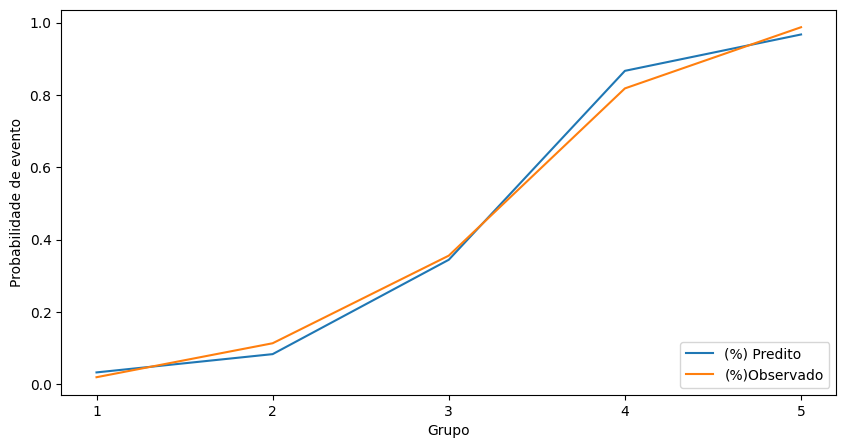

In [38]:
# - Compare graficamente o valor esperado versus observado para a taxa de maus por grupo

# Construindo gráfico de análise de calibração
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 1, 1)

# Metricas
ax = qualidade['taxa_eventos'].plot(label= '(%) Predito')
ax = qualidade['predito'].plot(label='(%)Observado')

# configuração
ticks = ax.set_xticks([0, 1, 2, 3, 4])
labels = ax.set_xticklabels([1, 2, 3, 4, 5])

# Legenda
ax.legend(loc="lower right")

# Labels
ax.set_ylabel('Probabilidade de evento')
ax.set_xlabel('Grupo');

In [39]:
# Indicadores de discriminação

# Acurácia 
acc = metrics.accuracy_score(df['flag_doente'],df['predito'] >.5)
print("Acurácia: {0:.2f}%".format(acc*100))

# AUC
fpr, tpr, thresholds = metrics.roc_curve(df['flag_doente'], df['predito'])
auc_ = metrics.auc(fpr, tpr)

# Gini 
gini = 2 * auc_ - 1

# KS
ks = ks_2samp(df.loc[df['flag_doente']==1, 'predito'], df.loc[df['flag_doente']==0, 'predito']).statistic

# Retorno
print('KS: {0:.2f}%\nAUC: {1:.2f}%\nGINI: {2:.2f}%'.format(ks*100, auc_*100, gini*100))

Acurácia: 88.12%
KS: 78.62%
AUC: 94.21%
GINI: 88.43%


| Métrica | Modelo anterior | Modelo atualizado | Variação |
|---|---:|---:|---:|
| **Acurácia** | 79,87% | **88,12%** | **+8,25 p.p.** |
| **AUC** | 86,21% | **94,21%** | **+8,00 p.p.** |
| **Gini** | 72,43% | **88,43%** | **+16,00 p.p.** |
| **KS** | 68,00% | **78,62%** | **+10,62 p.p.** |

#### Conclusão:

As variáveis adicionadas melhoraram o modelo, tanto estatisticamente (LRT) quanto em termos das métricas de desempenho solicitadas.